In [1]:

!pip -q install nltk scikit-learn textblob wordcloud tensorflow matplotlib

import re
import nltk
import numpy as np
import matplotlib.pyplot as plt

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from textblob import TextBlob
from wordcloud import WordCloud


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


In [2]:
#q1

text = """Artificial intelligence is transforming the world.
I enjoy learning about machine learning and new technologies.
AI helps people solve complex problems efficiently.
It is used in healthcare, education, and business.
I believe technology will make our future smarter and better."""

# Convert to lowercase and remove punctuation
clean_text = re.sub(r'[^\w\s]', '', text.lower())

# Tokenize into sentences and words
print("Clean Text:\n", clean_text)
print("\nSentences:", sent_tokenize(text))
print("\nWords:", word_tokenize(clean_text))

# Compare split() and word_tokenize()
print("\nUsing split():", clean_text.split())
print("\nUsing word_tokenize():", word_tokenize(clean_text))

# Remove stopwords
stop_words = set(stopwords.words('english'))
words = word_tokenize(clean_text)
filtered_words = [w for w in words if w not in stop_words]

print("\nWords after removing stopwords:", filtered_words)

# Word frequency distribution
freq = FreqDist(filtered_words)
print("\nWord Frequencies:", freq.most_common())


Clean Text:
 artificial intelligence is transforming the world
i enjoy learning about machine learning and new technologies
ai helps people solve complex problems efficiently
it is used in healthcare education and business
i believe technology will make our future smarter and better

Sentences: ['Artificial intelligence is transforming the world.', 'I enjoy learning about machine learning and new technologies.', 'AI helps people solve complex problems efficiently.', 'It is used in healthcare, education, and business.', 'I believe technology will make our future smarter and better.']

Words: ['artificial', 'intelligence', 'is', 'transforming', 'the', 'world', 'i', 'enjoy', 'learning', 'about', 'machine', 'learning', 'and', 'new', 'technologies', 'ai', 'helps', 'people', 'solve', 'complex', 'problems', 'efficiently', 'it', 'is', 'used', 'in', 'healthcare', 'education', 'and', 'business', 'i', 'believe', 'technology', 'will', 'make', 'our', 'future', 'smarter', 'and', 'better']

Using spl

In [3]:
#q2


# Extract alphabetic words only
words = re.findall(r'\b[a-zA-Z]+\b', text.lower())

# Remove stopwords
filtered = [w for w in words if w not in stop_words]

# Stemming and lemmatization
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed = [stemmer.stem(w) for w in filtered]
lemmatized = [lemmatizer.lemmatize(w) for w in filtered]

print("Original Words:", filtered)
print("\nStemmed Words:", stemmed)
print("\nLemmatized Words:", lemmatized)

print("\nComparison:")
print("Stemming cuts words to their root-like form.")
print("Lemmatization converts words to meaningful dictionary forms.")
print("Stemming is faster; lemmatization is generally more linguistically accurate.")


Original Words: ['artificial', 'intelligence', 'transforming', 'world', 'enjoy', 'learning', 'machine', 'learning', 'new', 'technologies', 'ai', 'helps', 'people', 'solve', 'complex', 'problems', 'efficiently', 'used', 'healthcare', 'education', 'business', 'believe', 'technology', 'make', 'future', 'smarter', 'better']

Stemmed Words: ['artifici', 'intellig', 'transform', 'world', 'enjoy', 'learn', 'machin', 'learn', 'new', 'technolog', 'ai', 'help', 'peopl', 'solv', 'complex', 'problem', 'effici', 'use', 'healthcar', 'educ', 'busi', 'believ', 'technolog', 'make', 'futur', 'smarter', 'better']

Lemmatized Words: ['artificial', 'intelligence', 'transforming', 'world', 'enjoy', 'learning', 'machine', 'learning', 'new', 'technology', 'ai', 'help', 'people', 'solve', 'complex', 'problem', 'efficiently', 'used', 'healthcare', 'education', 'business', 'believe', 'technology', 'make', 'future', 'smarter', 'better']

Comparison:
Stemming cuts words to their root-like form.
Lemmatization conve

In [4]:
#q3


texts = [
    "Artificial intelligence improves healthcare and education.",
    "Machine learning helps computers learn from data.",
    "Electric vehicles reduce pollution and save energy."
]

# Bag of Words
cv = CountVectorizer()
bow = cv.fit_transform(texts)

print("Bag of Words Matrix:")
print(bow.toarray())
print("Features:", cv.get_feature_names_out())

# TF-IDF
tfidf = TfidfVectorizer()
matrix = tfidf.fit_transform(texts)
features = tfidf.get_feature_names_out()

print("\nTop 3 TF-IDF Keywords for Each Text:")
for i, row in enumerate(matrix.toarray()):
    top_indices = row.argsort()[-3:][::-1]
    print(f"Text {i+1}:", [(features[j], round(row[j], 3))
                              for j in top_indices])

print("\nInterpretation:")
print("Bag of Words counts word occurrences.")
print("TF-IDF gives higher importance to words that are more distinctive.")


Bag of Words Matrix:
[[1 1 0 0 1 0 0 0 1 0 1 1 0 0 0 0 0 0 0]
 [0 0 1 1 0 0 0 1 0 1 0 0 1 1 1 0 0 0 0]
 [1 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 1 1 1]]
Features: ['and' 'artificial' 'computers' 'data' 'education' 'electric' 'energy'
 'from' 'healthcare' 'helps' 'improves' 'intelligence' 'learn' 'learning'
 'machine' 'pollution' 'reduce' 'save' 'vehicles']

Top 3 TF-IDF Keywords for Each Text:
Text 1: [('intelligence', np.float64(0.423)), ('healthcare', np.float64(0.423)), ('improves', np.float64(0.423))]
Text 2: [('learn', np.float64(0.378)), ('learning', np.float64(0.378)), ('machine', np.float64(0.378))]
Text 3: [('vehicles', np.float64(0.39)), ('save', np.float64(0.39)), ('reduce', np.float64(0.39))]

Interpretation:
Bag of Words counts word occurrences.
TF-IDF gives higher importance to words that are more distinctive.


In [5]:
#q4


text1 = """Artificial intelligence helps computers learn.
AI analyzes data and makes predictions.
It is useful in healthcare and education.
AI automates tasks and solves complex problems."""

text2 = """Blockchain stores information securely.
It uses decentralized digital ledgers.
Blockchain supports secure online transactions.
It improves transparency and data security."""

# Preprocessing and tokenization
def preprocess(t):
    t = re.sub(r'[^a-zA-Z\s]', '', t.lower())
    return set(word_tokenize(t))

set1 = preprocess(text1)
set2 = preprocess(text2)

# Jaccard similarity
jaccard = len(set1 & set2) / len(set1 | set2)
print("Jaccard Similarity:", round(jaccard, 4))

# Cosine similarity using TF-IDF
vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform([text1, text2])
cosine = cosine_similarity(tfidf_matrix[0:1], tfidf_matrix[1:2])[0][0]

print("Cosine Similarity:", round(cosine, 4))

print("\nAnalysis:")
print("Jaccard measures the overlap between unique words.")
print("Cosine similarity compares TF-IDF weighted word patterns.")
print("Cosine similarity is useful when word importance matters,")
print("while Jaccard is simple and easy to interpret.")


Jaccard Similarity: 0.0811
Cosine Similarity: 0.1261

Analysis:
Jaccard measures the overlap between unique words.
Cosine similarity compares TF-IDF weighted word patterns.
Cosine similarity is useful when word importance matters,
while Jaccard is simple and easy to interpret.


Sentiment Analysis:

Review: This product is amazing and works perfectly.
Polarity: 0.8
Subjectivity: 0.95
Sentiment: Positive

Review: I absolutely love this excellent product.
Polarity: 0.75
Subjectivity: 0.8
Sentiment: Positive

Review: The quality is good and the delivery was fast.
Polarity: 0.45
Subjectivity: 0.6
Sentiment: Positive

Review: This product is terrible and disappointing.
Polarity: -0.8
Subjectivity: 0.85
Sentiment: Negative

Review: Very poor quality and completely useless.
Polarity: -0.51
Subjectivity: 0.49
Sentiment: Negative

Review: I hate this product and would not recommend it.
Polarity: -0.8
Subjectivity: 0.9
Sentiment: Negative

Review: The product is okay and works as expected.
Polarity: 0.2
Subjectivity: 0.45
Sentiment: Positive



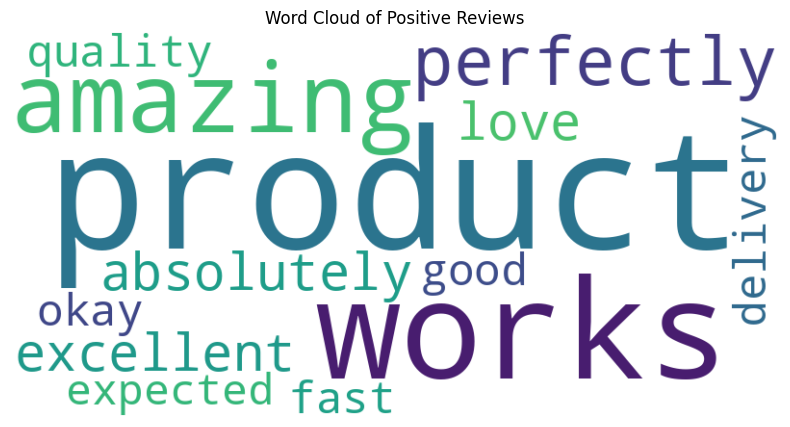

In [6]:
#q5


reviews = [
    "This product is amazing and works perfectly.",
    "I absolutely love this excellent product.",
    "The quality is good and the delivery was fast.",
    "This product is terrible and disappointing.",
    "Very poor quality and completely useless.",
    "I hate this product and would not recommend it.",
    "The product is okay and works as expected."
]

positive_reviews = []

print("Sentiment Analysis:\n")

for review in reviews:
    blob = TextBlob(review)
    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
        positive_reviews.append(review)
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print("Review:", review)
    print("Polarity:", round(polarity, 3))
    print("Subjectivity:", round(subjectivity, 3))
    print("Sentiment:", sentiment)
    print()

# Word cloud from positive reviews
positive_text = " ".join(positive_reviews)

wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Positive Reviews")
plt.show()


In [7]:
#q6


import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

tf.random.set_seed(42)
np.random.seed(42)

# Approximately 100 words of training data
training_text = """
Technology is changing the world in many ways.
Artificial intelligence helps people solve difficult problems.
Machine learning allows computers to learn from data.
Technology improves healthcare education and communication.
People use computers and smartphones every day.
Modern applications help businesses work faster.
Artificial intelligence can analyze information and make predictions.
Students use technology to learn new skills.
Technology also supports research and scientific discoveries.
Responsible use of technology can improve our lives.
The future will bring new ideas and exciting opportunities.
Technology connects people and makes information accessible.
Learning about technology helps us prepare for the future.
"""

# Tokenize text
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])

total_words = len(tokenizer.word_index) + 1
sequences = []

for line in training_text.lower().split('.'):
    seq = tokenizer.texts_to_sequences([line])[0]
    for i in range(2, len(seq) + 1):
        sequences.append(seq[:i])

# Prepare input and output sequences
max_len = max(len(s) for s in sequences)
padded = pad_sequences(sequences, maxlen=max_len, padding='pre')

X = padded[:, :-1]
y = padded[:, -1]

# Build LSTM model
model = Sequential([
    Embedding(total_words, 32),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# Train the model
model.fit(X, y, epochs=100, verbose=0)
print("Model training completed!")

# Generate text
def generate_text(seed, next_words=8):
    result = seed.lower()

    for _ in range(next_words):
        seq = tokenizer.texts_to_sequences([result])[0]
        seq = pad_sequences([seq], maxlen=max_len - 1, padding='pre')

        prediction = model.predict(seq, verbose=0)[0]
        next_index = int(np.argmax(prediction))

        if next_index == 0:
            break

        next_word = tokenizer.index_word.get(next_index)
        if next_word is None:
            break

        result += " " + next_word

    return result

print("\nGenerated Text:")
print("Line 1:", generate_text("technology", 8))
print("Line 2:", generate_text("artificial intelligence", 8))
print("Line 3:", generate_text("machine learning", 8))


Model training completed!

Generated Text:
Line 1: technology intelligence helps people solve information accessible predictions predictions
Line 2: artificial intelligence people people solve difficult problems predictions predictions opportunities
Line 3: machine learning allows computers to learn from data data data
